# Projeto SETA - Classificador supervisionado


### 1) Qual a base escolhida?

Forest Covertypes (Covertype Dataset): https://archive.ics.uci.edu/dataset/31/covertype

### 2) **(10%)** Pré-processamento: entendimento do conjunto de dados
- Quais são minhas features?
- Quais são minhas classes?
- Como estão distribuidas minhas classes?
- Checagem se os valores estão dentro de um limite permitido ou razoável.
- Tratamento de valores ausentes por eliminação ou substituição.
- Conversão do tipo de dados.


In [ ]:
from sklearn.datasets import fetch_covtype
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregando a base Forest Covertypes
covtype = fetch_covtype()

# Criando o DataFrame
df = pd.DataFrame(
    covtype.data,
    columns=covtype.feature_names
)

# Adicionando a variável alvo
df["Cover_Type"] = covtype.target

# Visualizando as primeiras linhas
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


In [ ]:
print(f'Quantidade de linhas: {df.shape[0]}')
print(f'Quantidade de colunas: {df.shape[1]}')

Quantidade de linhas: 581012
Quantidade de colunas: 55


Features:

In [ ]:
features = df.drop(columns=["Cover_Type"])

print("Quantidade de features:", features.shape[1])
print("\nFeatures:")
for feature in features.columns:
    print("-", feature)

Quantidade de features: 54

Features:
- Elevation
- Aspect
- Slope
- Horizontal_Distance_To_Hydrology
- Vertical_Distance_To_Hydrology
- Horizontal_Distance_To_Roadways
- Hillshade_9am
- Hillshade_Noon
- Hillshade_3pm
- Horizontal_Distance_To_Fire_Points
- Wilderness_Area_0
- Wilderness_Area_1
- Wilderness_Area_2
- Wilderness_Area_3
- Soil_Type_0
- Soil_Type_1
- Soil_Type_2
- Soil_Type_3
- Soil_Type_4
- Soil_Type_5
- Soil_Type_6
- Soil_Type_7
- Soil_Type_8
- Soil_Type_9
- Soil_Type_10
- Soil_Type_11
- Soil_Type_12
- Soil_Type_13
- Soil_Type_14
- Soil_Type_15
- Soil_Type_16
- Soil_Type_17
- Soil_Type_18
- Soil_Type_19
- Soil_Type_20
- Soil_Type_21
- Soil_Type_22
- Soil_Type_23
- Soil_Type_24
- Soil_Type_25
- Soil_Type_26
- Soil_Type_27
- Soil_Type_28
- Soil_Type_29
- Soil_Type_30
- Soil_Type_31
- Soil_Type_32
- Soil_Type_33
- Soil_Type_34
- Soil_Type_35
- Soil_Type_36
- Soil_Type_37
- Soil_Type_38
- Soil_Type_39


As features são as variáveis utilizadas pelo classificador para realizar a previsão do tipo de cobertura florestal. A variável Cover_Type não é considerada uma feature, pois representa a classe que queremos prever.

Classes:

In [ ]:
classes = df["Cover_Type"].unique()

print("Classes encontradas:")
print(sorted(classes))

print("\nQuantidade de classes:", df["Cover_Type"].nunique())

Classes encontradas:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7)]

Quantidade de classes: 7


A variável alvo é Cover_Type, que representa o tipo de cobertura florestal. A base possui 7 classes diferentes, identificadas pelos valores de 1 a 7.

Distribuição das classes:

In [ ]:
class_counts = df["Cover_Type"].value_counts().sort_index()

print(class_counts)

Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


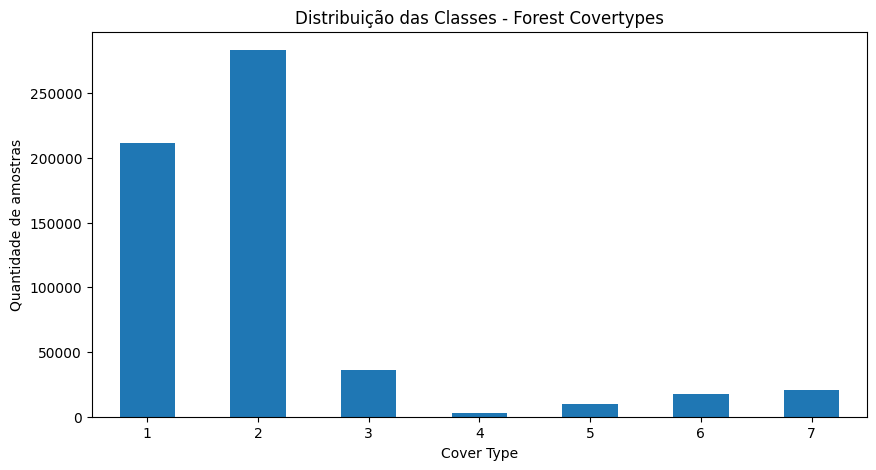

In [ ]:
plt.figure(figsize=(10, 5))

class_counts.plot(kind="bar")

plt.title("Distribuição das Classes - Forest Covertypes")
plt.xlabel("Cover Type")
plt.ylabel("Quantidade de amostras")
plt.xticks(rotation=0)

plt.show()

In [ ]:
class_percentage = df["Cover_Type"].value_counts(normalize=True).sort_index() * 100

print(class_percentage.round(2))

Cover_Type
1    36.46
2    48.76
3     6.15
4     0.47
5     1.63
6     2.99
7     3.53
Name: proportion, dtype: float64


A distribuição das classes não é uniforme. Algumas classes possuem uma quantidade de amostras significativamente maior que outras. Essa diferença deve ser considerada durante a avaliação dos classificadores, pois uma distribuição desbalanceada pode influenciar algumas métricas de desempenho.

Checagem dos valores:

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


In [ ]:
print("Valores infinitos:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Valores infinitos: 0


In [ ]:
print("Valores negativos:")
print((df.select_dtypes(include=np.number) < 0).sum().sort_values(ascending=False).head(20))

Valores negativos:
Vertical_Distance_To_Hydrology        55143
Aspect                                    0
Elevation                                 0
Slope                                     0
Horizontal_Distance_To_Hydrology          0
Horizontal_Distance_To_Roadways           0
Hillshade_9am                             0
Hillshade_Noon                            0
Hillshade_3pm                             0
Horizontal_Distance_To_Fire_Points        0
Wilderness_Area_0                         0
Wilderness_Area_1                         0
Wilderness_Area_2                         0
Wilderness_Area_3                         0
Soil_Type_0                               0
Soil_Type_1                               0
Soil_Type_2                               0
Soil_Type_3                               0
Soil_Type_4                               0
Soil_Type_5                               0
dtype: int64


Foi realizada uma análise estatística das variáveis numéricas utilizando medidas como mínimo, máximo, média e desvio padrão. Também foi verificada a existência de valores infinitos e valores negativos. Os resultados serão considerados no tratamento dos dados antes da aplicação dos classificadores.

Tratamento de valores ausentes:

In [ ]:
missing_values = df.isnull().sum()

print("Quantidade total de valores ausentes:", missing_values.sum())

print("\nColunas com valores ausentes:")
print(missing_values[missing_values > 0])

Quantidade total de valores ausentes: 0

Colunas com valores ausentes:
Series([], dtype: int64)


Não foram encontrados valores ausentes na base de dados. Dessa forma, não foi necessário realizar eliminação ou substituição de valores ausentes.

Conversão do tipo de dados:

In [ ]:
print(df.dtypes)

Elevation                             float64
Aspect                                float64
Slope                                 float64
Horizontal_Distance_To_Hydrology      float64
Vertical_Distance_To_Hydrology        float64
Horizontal_Distance_To_Roadways       float64
Hillshade_9am                         float64
Hillshade_Noon                        float64
Hillshade_3pm                         float64
Horizontal_Distance_To_Fire_Points    float64
Wilderness_Area_0                     float64
Wilderness_Area_1                     float64
Wilderness_Area_2                     float64
Wilderness_Area_3                     float64
Soil_Type_0                           float64
Soil_Type_1                           float64
Soil_Type_2                           float64
Soil_Type_3                           float64
Soil_Type_4                           float64
Soil_Type_5                           float64
Soil_Type_6                           float64
Soil_Type_7                       

In [ ]:
print("\nTipos de dados:")
print(df.dtypes.value_counts())


Tipos de dados:
float64    54
int32       1
Name: count, dtype: int64


Foi realizada a verificação dos tipos de dados presentes no conjunto. As variáveis utilizadas no modelo são predominantemente numéricas, portanto não foi necessária uma conversão significativa dos dados para que fossem utilizados pelos classificadores.

### 3) **(80%)** Nos blocos seguintes implemente seus classificadores (serão implementados 2 métodos diferentes).

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.96      0.94      0.95     42368
           2       0.95      0.97      0.96     56661
           3       0.94      0.96      0.95      7151
           4       0.92      0.86      0.89       549
           5       0.95      0.77      0.85      1899
           6       0.93      0.89      0.91      3473
           7       0.97      0.95      0.96      4102

    accuracy                           0.95    116203
   macro avg       0.95      0.91      0.92    116203
weighted avg       0.95      0.95      0.95    116203



#### 3.1) Qual método escolhido?

**Indique o método escolhido**

Random Forest

#### 3.2) **(10%)** Baseline - Implemente seu classificador da forma mais simples possível para esse ser seu baseline

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separando as features e a variável alvo
X = df.drop(columns=["Cover_Type"])
y = df["Cover_Type"]

# Dividindo os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (464809, 54)
Teste: (116203, 54)


In [ ]:
# Criando o classificador Random Forest
rf_baseline = RandomForestClassifier(
    random_state=42
)

# Treinando o modelo
rf_baseline.fit(X_train, y_train)

# Fazendo as previsões
y_pred = rf_baseline.predict(X_test)

# Calculando a acurácia
accuracy_baseline = accuracy_score(y_test, y_pred)

print("Acurácia do Baseline:", accuracy_baseline)

Acurácia do Baseline: 0.9533316695782381


#### 3.3) **(20%)** Versão 1 - O que podemos fazer para melhorar nosso baseline? Aplique técnicas como redução de dimensionalidade, normalização ou outras. Compare os resultados.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Pipeline com padronização + PCA + Random Forest
rf_v1 = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", RandomForestClassifier(random_state=42))
])

# Treinando o modelo
rf_v1.fit(X_train, y_train)

# Fazendo as previsões
y_pred_v1 = rf_v1.predict(X_test)

# Calculando a acurácia
accuracy_v1 = accuracy_score(y_test, y_pred_v1)

print("Acurácia da Versão 1:", accuracy_v1)

Acurácia da Versão 1: 0.9456640534237498


In [ ]:
print(classification_report(y_test, y_pred_v1))

              precision    recall  f1-score   support

           1       0.96      0.94      0.95     42368
           2       0.94      0.96      0.95     56661
           3       0.92      0.95      0.94      7151
           4       0.90      0.76      0.83       549
           5       0.92      0.76      0.83      1899
           6       0.90      0.86      0.88      3473
           7       0.96      0.95      0.95      4102

    accuracy                           0.95    116203
   macro avg       0.93      0.88      0.90    116203
weighted avg       0.95      0.95      0.95    116203



In [ ]:
pca = rf_v1.named_steps["pca"]

print("Número de features originais:", X_train.shape[1])
print("Número de componentes após PCA:", pca.n_components_)
print("Variância explicada:", pca.explained_variance_ratio_.sum())

Número de features originais: 54
Número de componentes após PCA: 43
Variância explicada: 0.9505150959414779


In [ ]:
PCA(n_components=0.95)

PCA(n_components=0.95)

Na versão 1 foi aplicada padronização dos dados utilizando StandardScaler e redução de dimensionalidade utilizando PCA, mantendo aproximadamente 95% da variância dos dados. Com isso, as 54 features originais foram reduzidas para 43 componentes.

O Baseline apresentou acurácia de 95,33%, enquanto a Versão 1 apresentou acurácia de 94,57%. Portanto, para este classificador e conjunto de dados, a aplicação da redução de dimensionalidade não proporcionou melhoria na acurácia. Apesar da redução de 54 para 43 dimensões, houve uma pequena perda de desempenho.

Também é possível observar uma redução nos resultados de algumas classes minoritárias, principalmente nas classes 4 e 5. Portanto, para o próximo estágio, será realizado o ajuste de hiperparâmetros do Random Forest buscando melhorar o desempenho do modelo.

#### 3.4) **(10%)** Tunning - Agora que temos um resultado promissor, vamos tentar melhorar o resultado alterando um ou mais hiper-parametro. Compare os resultados.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Testando diferentes configurações de hiperparâmetros
modelos = {
    "Baseline": RandomForestClassifier(
        random_state=42
    ),

    "Tuning 1": RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        min_samples_leaf=1,
        random_state=42
    ),

    "Tuning 2": RandomForestClassifier(
        n_estimators=100,
        max_depth=40,
        min_samples_leaf=1,
        random_state=42
    ),

    "Tuning 3": RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42
    )
}

resultados_tuning = {}

for nome, modelo in modelos.items():

    print(f"\nTreinando: {nome}")

    modelo.fit(X_train, y_train)

    previsoes = modelo.predict(X_test)

    acuracia = accuracy_score(y_test, previsoes)

    resultados_tuning[nome] = acuracia

    print(f"Acurácia: {acuracia:.4f}")


Treinando: Baseline
Acurácia: 0.9533

Treinando: Tuning 1
Acurácia: 0.9460

Treinando: Tuning 2
Acurácia: 0.9534

Treinando: Tuning 3
Acurácia: 0.9483


In [ ]:
print("\nComparação dos modelos:")

for modelo, resultado in resultados_tuning.items():
    print(f"{modelo}: {resultado:.4f}")


Comparação dos modelos:
Baseline: 0.9533
Tuning 1: 0.9460
Tuning 2: 0.9534
Tuning 3: 0.9483


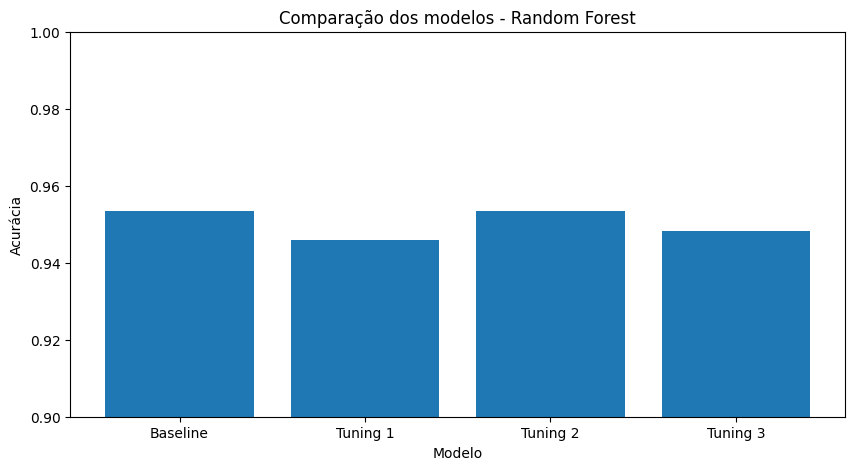

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    resultados_tuning.keys(),
    resultados_tuning.values()
)

plt.title("Comparação dos modelos - Random Forest")
plt.xlabel("Modelo")
plt.ylabel("Acurácia")

plt.ylim(0.90, 1.00)

plt.show()

Foram testadas diferentes configurações de hiperparâmetros do Random Forest. O Baseline apresentou acurácia de 95,33%. O Tuning 1 apresentou 94,60%, enquanto o Tuning 2 apresentou 95,34% e o Tuning 3 apresentou 94,83%.

Entre as configurações testadas, o Tuning 2 apresentou a maior acurácia, com 95,34%, representando uma pequena melhoria em relação ao Baseline. Portanto, entre as configurações avaliadas, o Tuning 2 apresentou o melhor resultado de acurácia.

#### 3.5) Qual método escolhido?

**Indique o método escolhido**

K-Nearest Neighbors (KNN)

#### 3.6) **(10%)** Baseline - Implemente seu classificador da forma mais simples possível para esse ser seu baseline

Importação:

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

Criando o modelo:

In [ ]:
# Criando o classificador KNN
knn_baseline = KNeighborsClassifier()

# Treinando o modelo
knn_baseline.fit(X_train, y_train)

# Fazendo as previsões
y_pred_knn = knn_baseline.predict(X_test)

# Calculando a acurácia
accuracy_knn_baseline = accuracy_score(y_test, y_pred_knn)

print("Acurácia do KNN Baseline:", accuracy_knn_baseline)

Acurácia do KNN Baseline: 0.9679956627625793


Relatório de classificação:

In [ ]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           1       0.97      0.97      0.97     42368
           2       0.97      0.98      0.97     56661
           3       0.96      0.97      0.96      7151
           4       0.91      0.79      0.84       549
           5       0.92      0.89      0.91      1899
           6       0.94      0.93      0.94      3473
           7       0.97      0.96      0.97      4102

    accuracy                           0.97    116203
   macro avg       0.95      0.93      0.94    116203
weighted avg       0.97      0.97      0.97    116203



#### 3.7) **(20%)** Versão 1 - O que podemos fazer para melhorar nosso baseline? Aplique técnicas como redução de dimensionalidade, normalização ou outras. Compare os resultados.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Criando o pipeline com padronização + KNN
knn_v1 = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier())
])

# Treinando o modelo
knn_v1.fit(X_train, y_train)

# Fazendo as previsões
y_pred_knn_v1 = knn_v1.predict(X_test)

# Calculando a acurácia
accuracy_knn_v1 = accuracy_score(y_test, y_pred_knn_v1)

print("Acurácia do KNN Versão 1:", accuracy_knn_v1)

Acurácia do KNN Versão 1: 0.9284355825581095


In [ ]:
print(classification_report(y_test, y_pred_knn_v1))

              precision    recall  f1-score   support

           1       0.93      0.93      0.93     42368
           2       0.94      0.95      0.94     56661
           3       0.90      0.91      0.91      7151
           4       0.84      0.72      0.78       549
           5       0.84      0.76      0.80      1899
           6       0.82      0.81      0.82      3473
           7       0.94      0.93      0.94      4102

    accuracy                           0.93    116203
   macro avg       0.89      0.86      0.87    116203
weighted avg       0.93      0.93      0.93    116203



Na Versão 1 foi aplicada a padronização das features utilizando o StandardScaler antes da aplicação do KNN. O objetivo foi colocar as variáveis em uma escala comparável, considerando que o KNN utiliza medidas de distância para realizar a classificação.

O KNN Baseline apresentou acurácia de 96,80%, enquanto a Versão 1 apresentou acurácia de 92,84%. Portanto, neste experimento, a aplicação da padronização resultou em uma redução do desempenho do classificador.

Dessa forma, a padronização não apresentou melhoria para o KNN nesta configuração. Para a próxima etapa, serão testados diferentes hiperparâmetros do algoritmo, buscando verificar se é possível obter um desempenho superior.

#### 3.8) **(10%)** Tunning - Agora que temos um resultado promissor, vamos tentar melhorar o resultado alterando um ou mais hiper-parametro. Compare os resultados.

In [ ]:
# Implementação. Use mais blocos se achar que ficará mais organizado.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Valores de K que serão testados
valores_k = [3, 5, 7, 11]

resultados_knn = {}

for k in valores_k:

    print(f"Treinando KNN com k={k}...")

    modelo = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo.fit(X_train, y_train)

    previsoes = modelo.predict(X_test)

    acuracia = accuracy_score(y_test, previsoes)

    resultados_knn[k] = acuracia

    print(f"Acurácia: {acuracia:.4f}")

Treinando KNN com k=3...
Acurácia: 0.9679
Treinando KNN com k=5...
Acurácia: 0.9680
Treinando KNN com k=7...
Acurácia: 0.9653
Treinando KNN com k=11...
Acurácia: 0.9589


In [ ]:
print("\nComparação dos valores de K:")

for k, acuracia in resultados_knn.items():
    print(f"K={k}: {acuracia:.4f}")


Comparação dos valores de K:
K=3: 0.9679
K=5: 0.9680
K=7: 0.9653
K=11: 0.9589


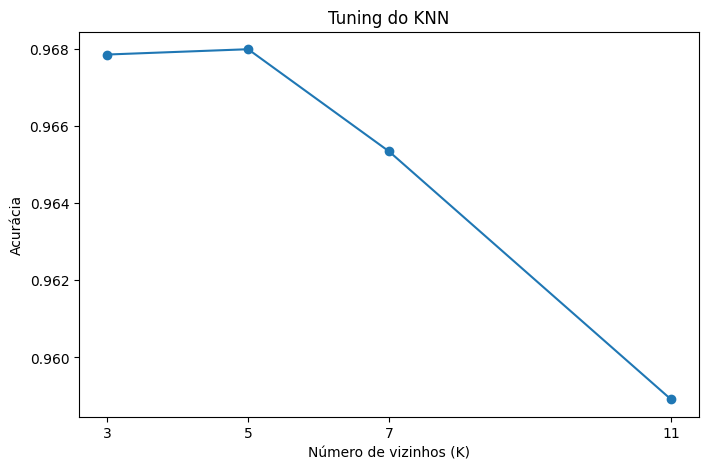

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(resultados_knn.keys()),
    list(resultados_knn.values()),
    marker="o"
)

plt.title("Tuning do KNN")
plt.xlabel("Número de vizinhos (K)")
plt.ylabel("Acurácia")
plt.xticks(valores_k)

plt.show()

Foram testados diferentes valores do hiperparâmetro K do algoritmo KNN, utilizando K=3, K=5, K=7 e K=11.

O modelo com K=3 apresentou acurácia de 96,79%, enquanto K=5 apresentou 96,80%. Para K=7, a acurácia foi de 96,53%, e para K=11 foi de 95,89%.

Entre as configurações testadas, o melhor resultado foi obtido com K=5, apresentando acurácia de 96,80%. Esse resultado é ligeiramente superior ao KNN Baseline, que apresentou 96,80% de acurácia, portanto a alteração do valor de K praticamente não modificou o desempenho do modelo.

Observa-se também que o aumento do número de vizinhos acima de 5 provocou uma redução gradual da acurácia. Assim, entre os valores testados, K=5 foi utilizado como configuração final do KNN.

### 5) **(10%)** Conclusões

*Compare seus resultados. Imaginando que sua solução fosse para produção, qual deles você escolheria? Por que? Quais os riscos você enxerga? O que recomendaria de próximos passos para melhorar os resultados?*

Foram avaliados dois classificadores supervisionados diferentes: Random Forest e K-Nearest Neighbors (KNN).

No Random Forest, o modelo Baseline apresentou acurácia de 95,33%. Na Versão 1, foi aplicada redução de dimensionalidade utilizando PCA, reduzindo as 54 features originais para 43 componentes e mantendo aproximadamente 95% da variância. Essa alteração resultou em uma acurácia de 94,57%, apresentando uma pequena redução no desempenho. No ajuste de hiperparâmetros, a melhor configuração testada apresentou acurácia de 95,34%, utilizando 100 árvores, profundidade máxima de 40 e `min_samples_leaf=1`.

No KNN, o modelo Baseline apresentou acurácia de 96,80%. Na Versão 1, foi aplicada a padronização das features utilizando StandardScaler, porém a acurácia caiu para 92,84%. No tuning, foram testados diferentes valores de K. O melhor resultado foi obtido com K=5, apresentando acurácia de 96,80%.

Comparando os resultados obtidos, o KNN apresentou a maior acurácia entre os modelos testados, enquanto o Random Forest apresentou resultados próximos, com aproximadamente 95% de acurácia. A redução de dimensionalidade aplicada ao Random Forest e a padronização aplicada ao KNN não produziram melhoria nos resultados obtidos neste experimento.

Em um cenário de produção, a escolha do modelo dependeria não somente da acurácia, mas também de fatores como tempo de treinamento, tempo de predição, quantidade de dados, custo computacional, facilidade de manutenção e comportamento do modelo diante de novos dados.

Entre os riscos identificados, está a diferença na distribuição das classes do conjunto de dados, pois algumas classes possuem uma quantidade de exemplos muito menor que outras. Isso pode fazer com que o modelo apresente um desempenho diferente entre as classes, mesmo quando a acurácia geral é alta.

Como próximos passos, seria interessante realizar uma avaliação mais completa utilizando outras métricas, como precisão, recall e F1-score por classe, além de testar outras configurações de hiperparâmetros e técnicas de validação cruzada. Também poderia ser avaliado o comportamento dos modelos com novos dados antes de uma utilização em produção.